# Can anyone read the text in your figure?

You draw a figure on a screen, as big as you like. A journal then prints it in a column about
5 inches wide. The whole figure is shrunk to fit, and its text is shrunk with it. On a figure
drawn 13 inches wide, text that was 10 pt on your screen comes out at 4 pt on the page, less than
half the size of the words round it.

Nothing warns you about this. The figure looks fine on screen, and the first time you see the
problem is in the proof. figfont shows you the printed size before that, sets the text to the size
you want on the page, and repairs the layout that bigger text breaks.

## In real life it is two lines

You tell figfont two things: **how wide the journal prints the figure**, and, if you want,
**the size the text should have on the page**. It works out the rest.

```python
set_printed_fonts(fig, printed_width=5.15)   # the text now prints at 7 and 8 pt
figfont.fit(fig)                             # repair whatever the bigger text pushed together
fig.savefig("fig01.pdf")
```

To choose the sizes yourself, add them: `set_printed_fonts(fig, printed_width=5.15, sizes={"tick": 8, "label": 9})`.

That is all you do on a real figure. The rest of this notebook goes through those two lines
slowly: what each one does, how it does it, and how to check the result.

**Part 1** takes one figure all the way through:

1. Draw a figure the usual way
2. See it the way a reader will
3. Measure how small the text is
4. Make the text the right size
5. See what the bigger text broke
6. Fix it
7. Check the file you will send

**Part 2** covers four other cases: a grid of small panels, labels on a map, a figure you only
have as a file, and working out sizes by hand.

Two words used all the way through:

- **Point (pt)**: the unit of text height. 72 pt is one inch. The main text of a paper is about
  10 pt and a footnote about 8 pt.
- **Printed size**: the size text has on the journal's page, after the figure has been shrunk to
  fit. It is the only size a reader ever sees.

You need to know matplotlib and nothing else. Every cell's output is saved here, so you can read
this from top to bottom without running it. To run it yourself:

```bash
git clone https://github.com/jake-casselman/figfont
cd figfont
pip install -e ".[mac]" jupyter cartopy
jupyter lab docs/tour.ipynb
```

(On Linux or Windows use `".[tesseract]"` and install the tesseract command.)

In [1]:
# notebook settings: show each figure whole and sharp
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_format = "retina"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import figfont
from figfont.mpl import scale_fonts, set_printed_fonts

# three drawing helpers for this notebook only (docs/tour_helpers.py); they are not part of figfont
from tour_helpers import against_papers, mark, on_the_page

out = Path("tour_output")    # the files this notebook saves
out.mkdir(exist_ok=True)

# Part 1: one figure, start to finish

## 1. Draw a figure the usual way

Three panels, 13 in wide, because that is comfortable on a screen. This is plain matplotlib with
its own 10 pt text. Nothing here uses figfont.

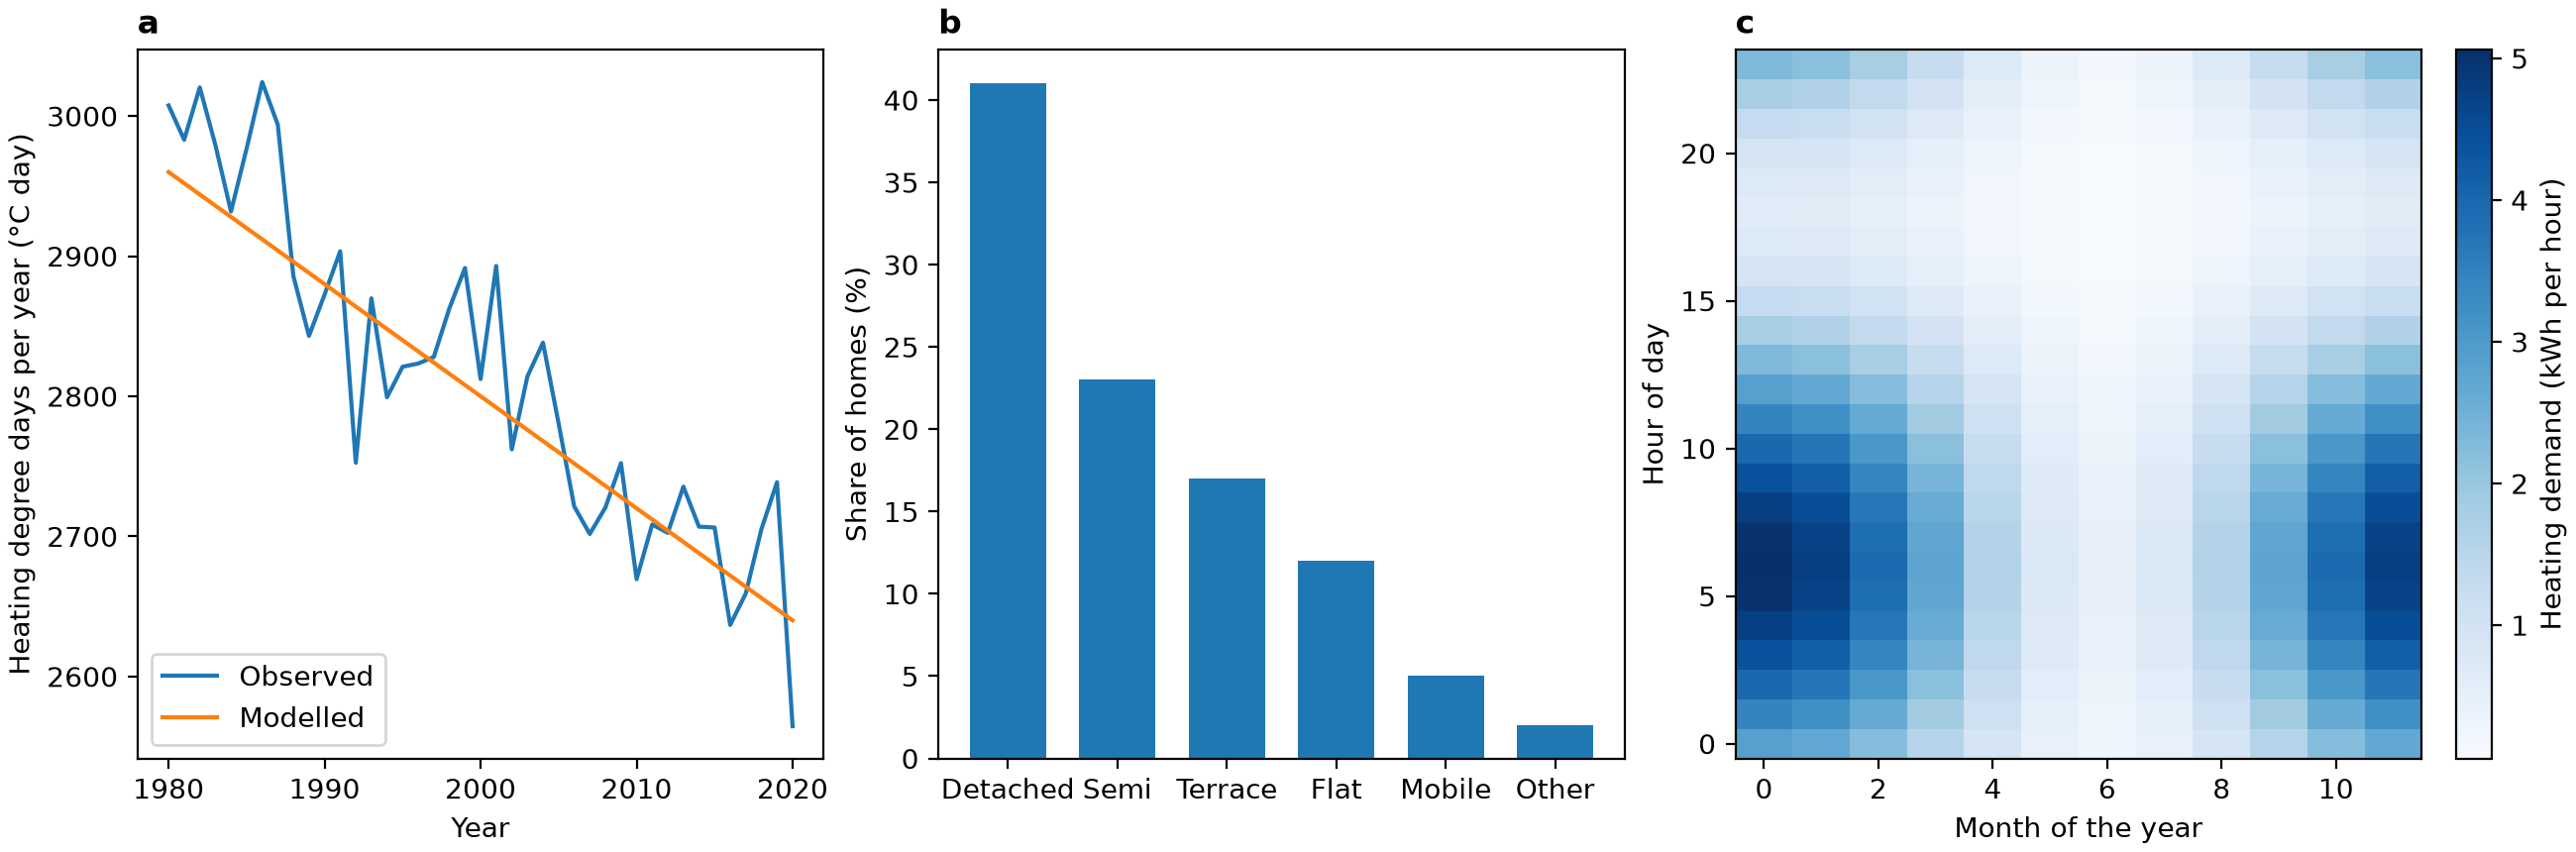

In [2]:
def draft():
    rng = np.random.default_rng(0)
    fig, (a, b, c) = plt.subplots(1, 3, figsize=(13, 4.3), layout="constrained")
    years = np.arange(1980, 2021)
    a.plot(years, 3000 - 9 * (years - 1980) + rng.normal(0, 60, years.size), label="Observed")
    a.plot(years, 2960 - 8 * (years - 1980), label="Modelled")
    a.set_xlabel("Year")
    a.set_ylabel("Heating degree days per year (°C day)")
    a.legend(loc="lower left")
    b.bar(["Detached", "Semi", "Terrace", "Flat", "Mobile", "Other"], [41, 23, 17, 12, 5, 2], width=0.7)
    b.set_ylabel("Share of homes (%)")
    month, hour = np.meshgrid(np.arange(12), np.arange(24))
    demand = (1.2 + np.cos(2 * np.pi * month / 12)) * (1.3 + np.cos(2 * np.pi * (hour - 6) / 24))
    image = c.imshow(demand, aspect="auto", cmap="Blues", origin="lower")
    fig.colorbar(image, ax=c).set_label("Heating demand (kWh per hour)")
    c.set_xlabel("Month of the year")
    c.set_ylabel("Hour of day")
    for letter, ax in zip("abc", (a, b, c)):
        ax.set_title(letter, loc="left", fontweight="bold")
    return fig

fig = draft()

It looks fine. Every word is easy to read.

## 2. See it the way a reader will

The journal does not print this figure 13 in wide. It places it across the text column, which
here is 5.15 in. Below is the same figure at that width, in a column of 10 pt text like the paper's.

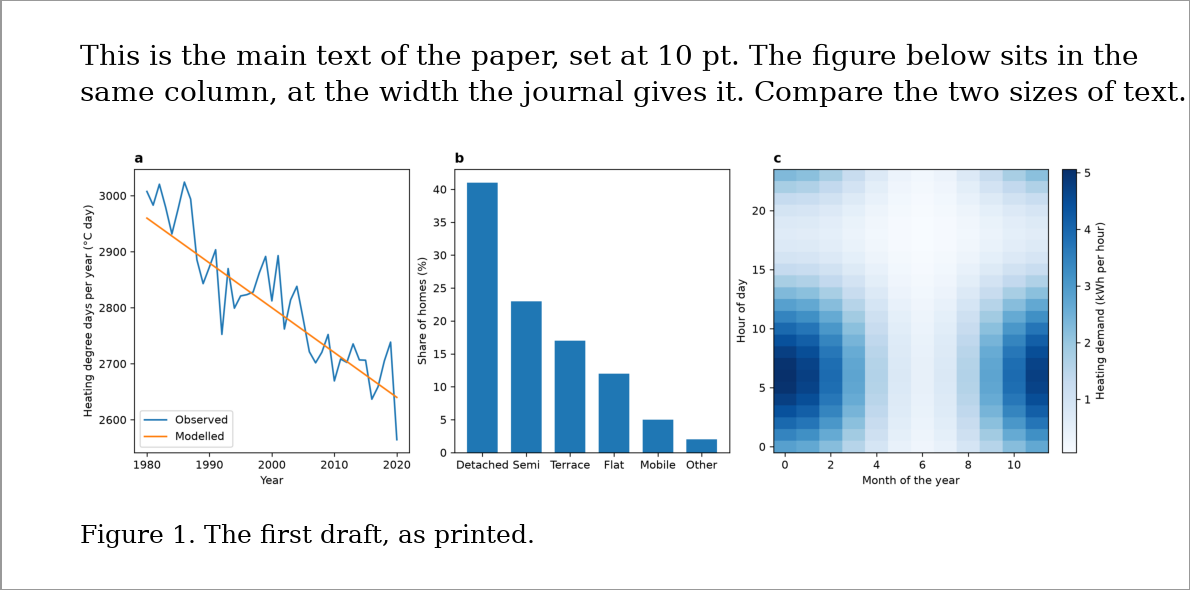

In [3]:
DRAWN = 13      # the width the figure is drawn at, inches
PAGE = 5.15     # the width the journal prints it at, inches

on_the_page(fig, PAGE, "The first draft, as printed.");

The axis numbers and labels are less than half the height of the text above them. That is the
problem this package is for.

**Where the page width comes from.** It is the one number you have to supply. The journal's author
guidelines give it, usually as a single-column width (about 3.5 in) and a full-page width (about
7 in). If you write in LaTeX, put `\the\textwidth` in the document and it prints the width in
points; divide by 72.27 to get inches. The 5.15 in used here is the text width of the Springer
Nature LaTeX template.

## 3. Measure how small the text is

Save the figure and give the file and the page width to `figfont.figure`. It reads every piece of
text in the file (each tick number, each label, each title) and works out the height it has on the
page.

In [4]:
fig.savefig(out / "draft.pdf")

measured = figfont.figure(out / "draft.pdf", printed_width=PAGE)

print(f"{measured.n} pieces of text. The typical one prints at {measured.median} pt.")

52 pieces of text. The typical one prints at 3.96 pt.


4 pt, where the paper's own text is 10 pt. `summary()` gives the spread as well:

In [5]:
measured.summary()

{'name': 'draft.pdf',
 'method': 'text',
 'n': 52,
 'median_pt': 3.96,
 'p10_pt': 3.96,
 'p90_pt': 3.96}

| Key | What it tells you |
|---|---|
| `name` | the file that was measured |
| `n` | how many pieces of text it found |
| `median_pt` | the typical size: half the pieces are smaller, half bigger |
| `p10_pt` | the small end: one piece in ten is smaller than this. This is the number to watch, because the smallest text is what a reader cannot make out |
| `p90_pt` | the big end: one piece in ten is bigger than this |
| `method` | `text` means the sizes were read from the PDF and are exact. `ocr` means they were estimated from an image (Part 2) |

All three sizes are the same here because the draft uses one font size for everything.

### Is 4 pt really too small?

figfont comes with the sizes of figure text in 111 published articles from 62 journals, measured
the same way. `verdict` compares your figure with them.

In [6]:
figfont.verdict(measured)

{'name': 'draft.pdf',
 'method': 'text',
 'n': 52,
 'median_pt': 3.96,
 'p10_pt': 3.96,
 'p90_pt': 3.96,
 'reference_median_pt': 7.97,
 'reference_range_pt': [7.39, 8.97],
 'verdict': 'small',
 'scale_to_reference': 2.01}

The first six keys are the summary again. The new ones:

| Key | What it tells you |
|---|---|
| `reference_median_pt` | the typical size of figure text in the published papers: 8 pt |
| `reference_range_pt` | half of the papers have their typical size inside this range, 7.4 to 9.0 pt |
| `verdict` | `small`, `ok` or `large`: where your figure sits against that range. It is also `small` when a tenth of the text is under 6 pt |
| `scale_to_reference` | what to multiply your font sizes by to match the published papers. Here 2: the text has to be twice as big |

The same thing as a picture. The dot is this figure; the grey band is where published papers sit.

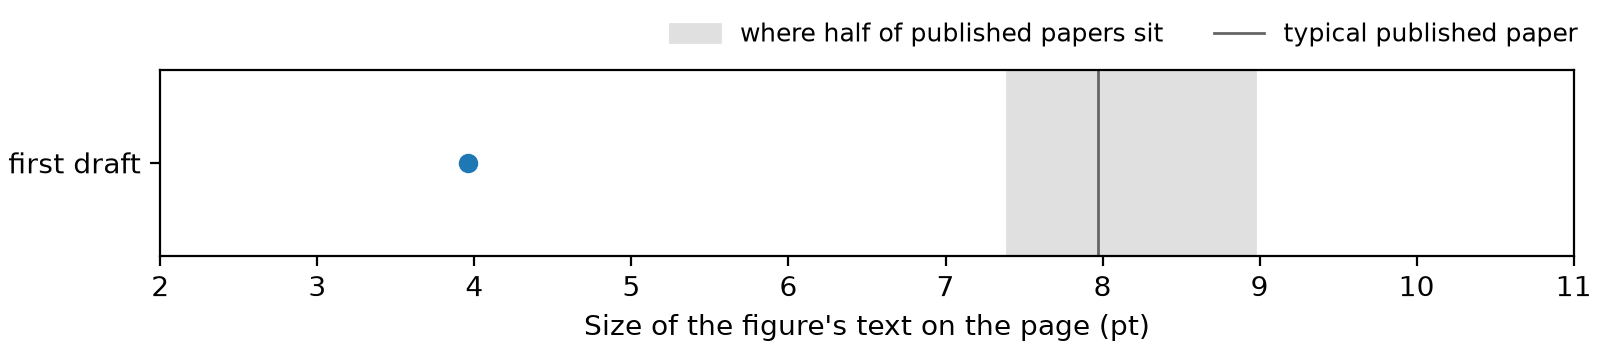

In [7]:
against_papers({"first draft": measured});

## 4. Make the text the right size

You could multiply every font size by 2 by hand, and do it again each time the figure changes
shape. `set_printed_fonts` does it from the page width: it sets every piece of text so that it
**prints** at the size you ask for. Left alone, it uses 7 pt for tick numbers and 8 pt for
everything else.

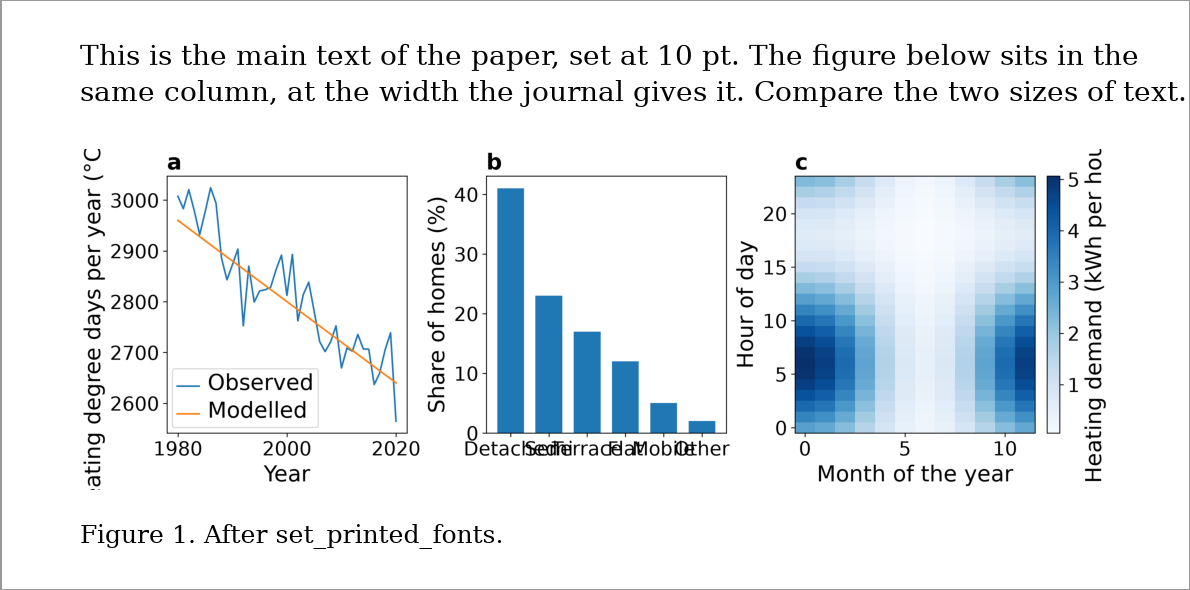

In [8]:
set_printed_fonts(fig, printed_width=PAGE)

on_the_page(fig, PAGE, "After set_printed_fonts.");

The text now matches the text round it. To pick other sizes, pass them:
`set_printed_fonts(fig, PAGE, sizes={"tick": 8})`. The names are `tick` (tick numbers), `label`
(axis and colour-bar labels), `title` (panel titles), `legend` and `other` (everything else).

**How it does it.** One multiplication. The figure is drawn 13 in wide and printed 5.15 in wide,
so everything on it shrinks to 5.15 / 13 = 0.40 of its size. For text to print at 8 pt it has to
be drawn at 8 / 0.40 = 20.2 pt. `set_printed_fonts` goes through every piece of text in the
figure, sees which kind it is, and sets it to the drawn size that prints at the size you asked
for. It changes font sizes and nothing else.

In [9]:
label = fig.axes[0].yaxis.label
tick = fig.axes[0].get_xticklabels()[0]

print(f"On the page the figure is {PAGE / DRAWN:.2f} of the size it is drawn at.")
print(f"The y-axis label is drawn at {label.get_fontsize():.1f} pt and prints at {label.get_fontsize() * PAGE / DRAWN:.1f} pt.")
print(f"A tick number is drawn at {tick.get_fontsize():.1f} pt and prints at {tick.get_fontsize() * PAGE / DRAWN:.1f} pt.")

On the page the figure is 0.40 of the size it is drawn at.
The y-axis label is drawn at 20.2 pt and prints at 8.0 pt.
A tick number is drawn at 17.7 pt and prints at 7.0 pt.


The sizes come from the width the figure has when you call it. If you change the figure's width
afterwards, call it again.

But look closely at the figure. The names under the bars run into each other, and the labels at
the left and right edges are cut off. Doubling the text broke the layout, as it always does.

## 5. See what the bigger text broke

`report_overlaps` lists every piece of text that touches other text or lies on the next panel.
With `edges=True` it also lists text that runs off the edge of the figure.

In [10]:
found = figfont.report_overlaps(fig, "fig01", edges=True)

TEXT OFF THE FIGURE fig01: 'Heating degree days per year (°C day)'


TEXT OVERLAP fig01: 'Detached' <-> 'Semi'


TEXT OVERLAP fig01: 'Detached' <-> 'Terrace'


TEXT OVERLAP fig01: 'Detached' <-> '0'


TEXT OVERLAP fig01: 'Semi' <-> 'Terrace'


TEXT OVERLAP fig01: 'Terrace' <-> 'Flat'


TEXT OVERLAP fig01: 'Flat' <-> 'Mobile'


TEXT OVERLAP fig01: 'Mobile' <-> 'Other'


TEXT OFF THE FIGURE fig01: 'Heating demand (kWh per hour)'


Each line is one problem. `TEXT OVERLAP` names two pieces of text that touch.
`TEXT OFF THE FIGURE` names a piece that is cut off at the edge. `fig01` is only a name for the
figure, so you can tell figures apart when you check several.

`overlaps` returns the same problems as a list you can use in code. Here each one gets a red box:

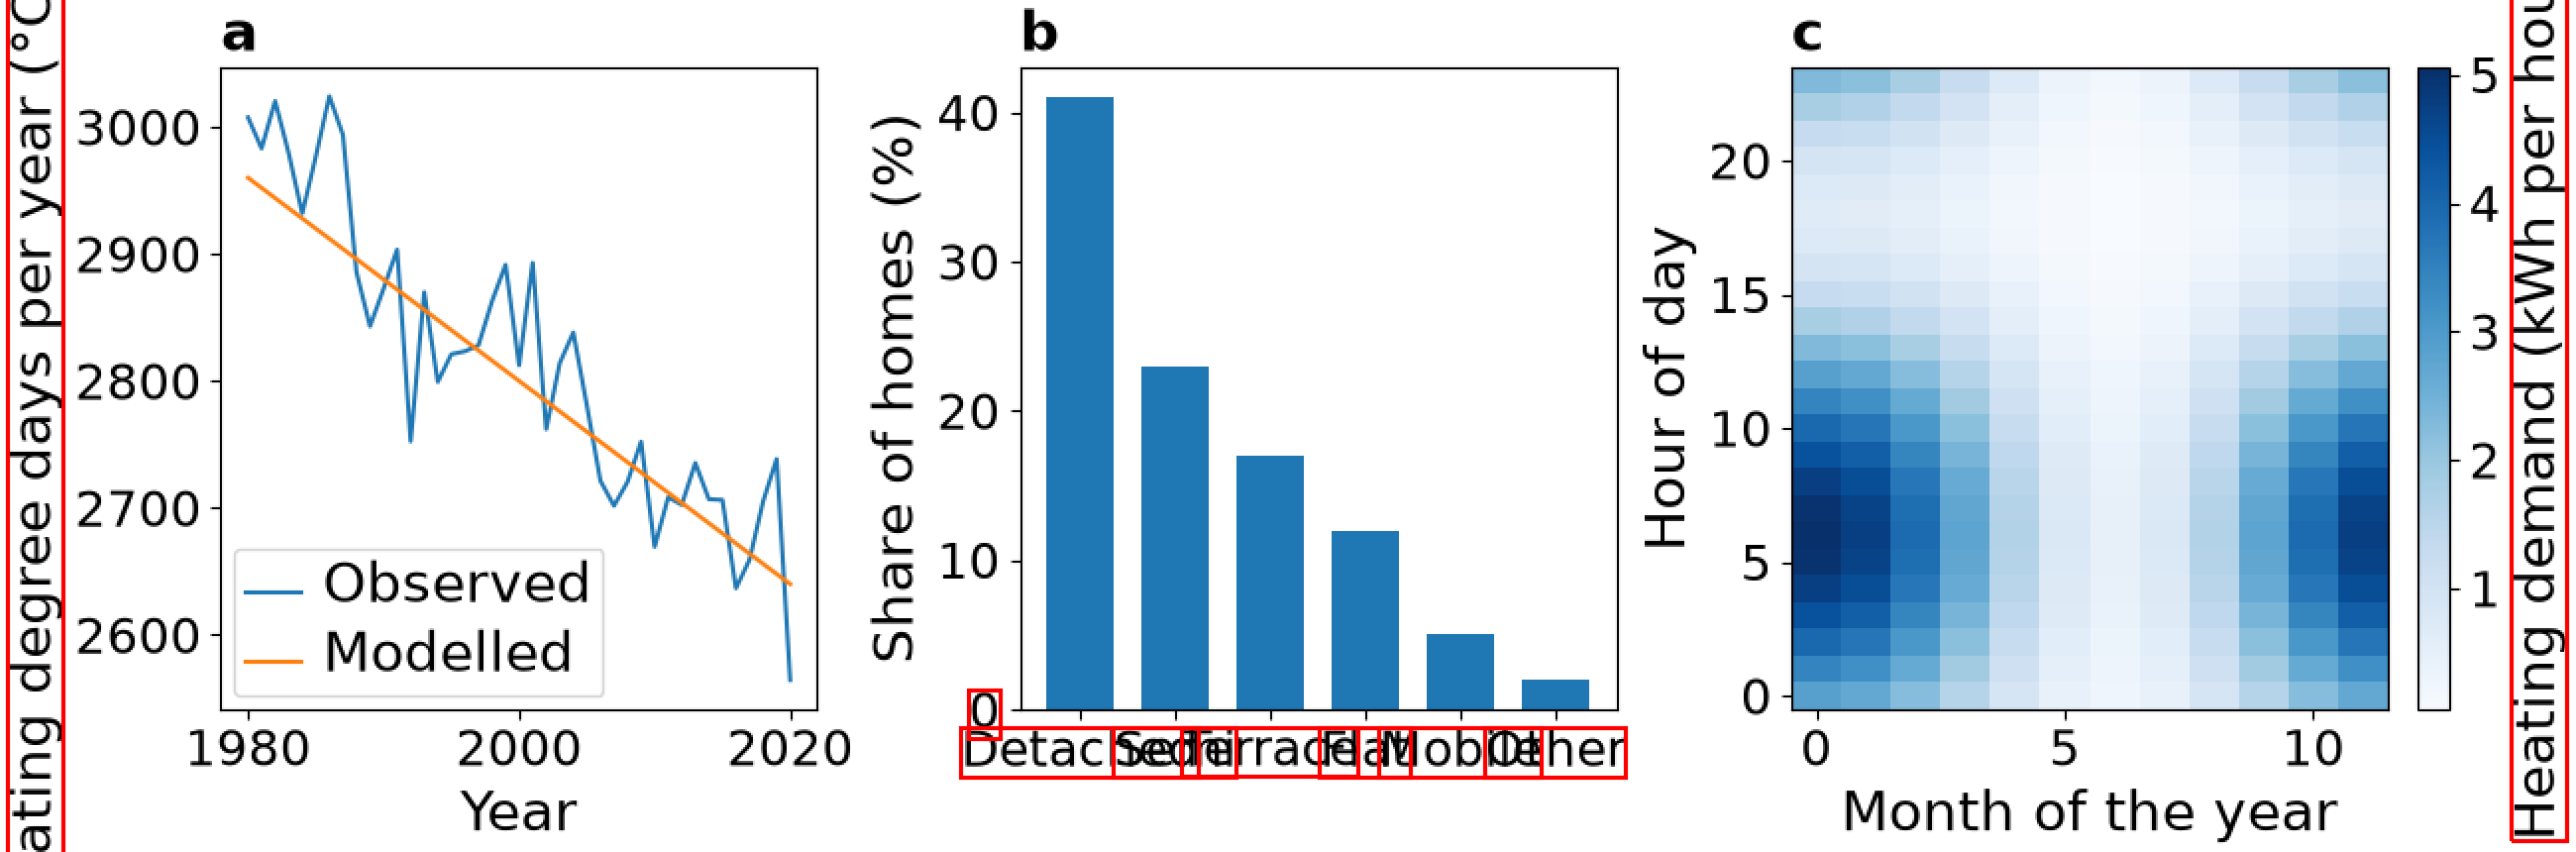

In [11]:
problems = figfont.overlaps(fig, edges=True)

mark(fig, problems);

## 6. Fix it

You could fix these one at a time: tilt the bar names, break the long labels in two, add space.
`fit` does that for you. For each problem it tries the smallest change that clears it.

It never changes a font size, a colour, the data, the wording or the width of the figure, so the
sizes you set in step 4 stay as they are.

0 problems left


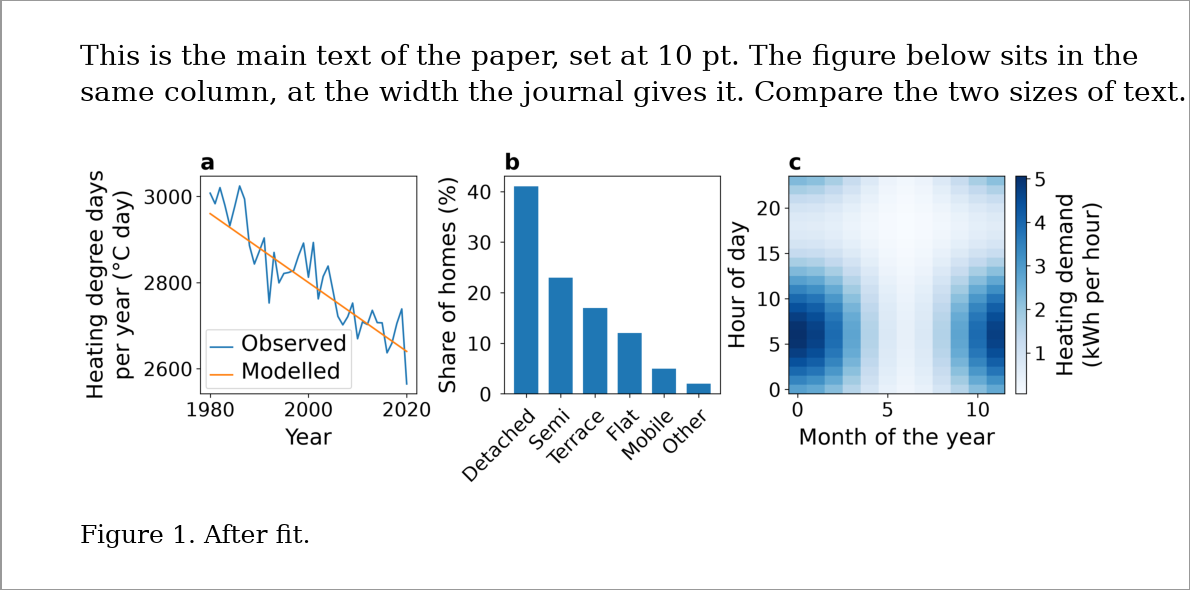

In [12]:
left = figfont.fit(fig, "fig01", edges=True, quiet=True)
print(left, "problems left")

on_the_page(fig, PAGE, "After fit.");

Three things changed: the two long labels went onto two lines, the axis labels moved clear of
their numbers, and the bar names were tilted. You can see the changes on the figure itself:

In [13]:
a, b, c = fig.axes[:3]

print("The y-axis label of panel a is now:", repr(a.get_ylabel()))
print("The bar names are tilted by", b.get_xticklabels()[0].get_rotation(), "degrees.")
print("The figure is still", fig.get_figwidth(), "in wide.")

The y-axis label of panel a is now: 'Heating degree days\nper year (°C day)'
The bar names are tilted by 45.0 degrees.
The figure is still 13.0 in wide.


### How `fit` works

It does what you would do by eye, over and over until nothing touches:

1. **It draws the figure in memory and asks matplotlib for the box round every piece of text.**
   Once a figure is drawn, matplotlib knows exactly where each tick number, label, title and
   legend entry sits.
2. **It finds the boxes that touch.** Two pieces of text collide when their boxes overlap. This is
   the list you saw in step 5.
3. **It makes the smallest repair for each collision**, from this list:

   | What it finds | What it does |
   |---|---|
   | A title or axis label longer than its panel, touching other text or running off the figure | Puts it on two lines. The words stay the same |
   | An axis label touching its own tick numbers | Moves the label out, clear of the numbers |
   | Tick labels touching their neighbours | Tilts them 30 degrees, then 45, 60 or 90 if they still touch |
   | A panel letter (a, b, c) sitting on its panel's labels | Moves it left, with the other letters in its column |
   | A note inside a panel that runs past the panel's side | Moves it back inside |
   | Two notes in one panel that touch | Pushes them apart |
   | A legend touching a label | Moves the legend up or down, away from it |
   | A legend lying on what the panel draws (a map, bars) | Moves it to an empty corner, or under the panel |

4. **It draws the figure again and looks again**, because one repair can cause a new collision.
5. **If text from two panels still touches, it adds space between the panels**, a little at a
   time. For panels above each other, the figure gets taller. The figure never gets wider, because
   the width is what sets the printed size of the text.

It stops when nothing touches, or when its repairs stop making a difference. It returns the number
of problems that are left (here 0), so you know whether anything still needs your eye.

Without `quiet=True`, `fit` prints what it changed. Part 2 shows that output.

## 7. Check the file you will send

Save the figure and measure the file again, exactly as in step 3.

In [14]:
fig.savefig(out / "fig01.pdf")
fig.savefig(out / "fig01.png", dpi=300)

final = figfont.figure(out / "fig01.pdf", printed_width=PAGE)

print(f"Typical text: {final.median} pt. Small end: {final.percentile(10)} pt. Big end: {final.percentile(90)} pt.")
print("Against all papers:", figfont.verdict(final)["verdict"])
print("Against Nature:    ", figfont.verdict(final, journal="Nature")["verdict"])

Typical text: 7.0 pt. Small end: 7.0 pt. Big end: 8.0 pt.
Against all papers: small
Against Nature:     ok


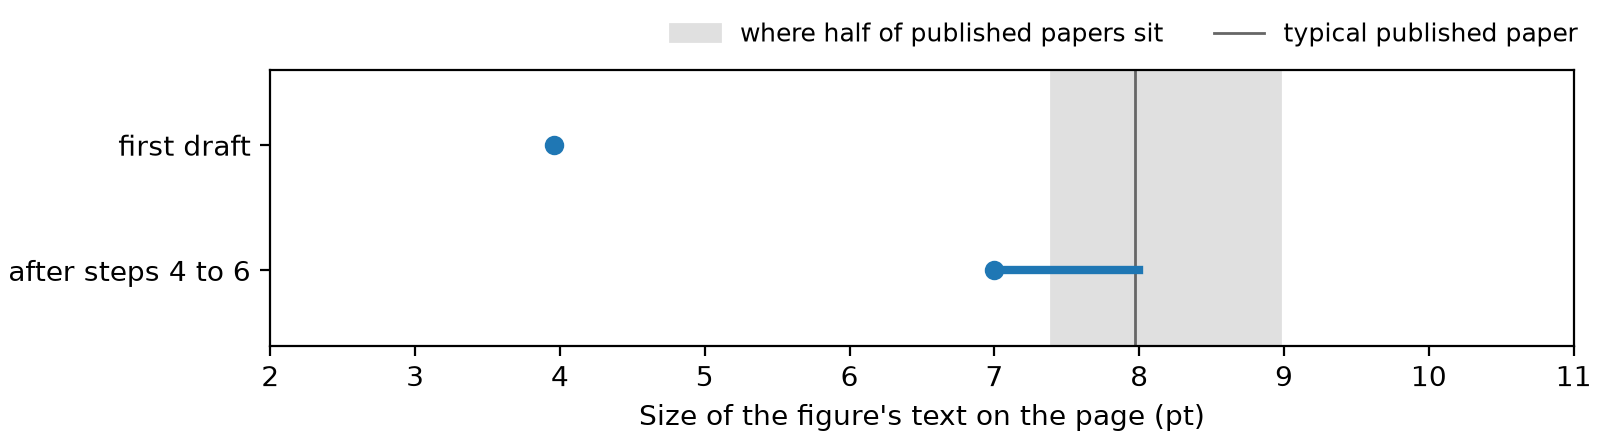

In [15]:
against_papers({"first draft": measured, "after steps 4 to 6": final});

The text went from 4 pt to between 7 and 8 pt, and nothing collides.

The verdict against all papers is still `small`, by a narrow margin. Most pieces of text in a
figure are tick numbers, and those are at 7 pt, just under the 7.4 pt where the grey band starts.
The labels and titles, at 8 pt, are in the middle of it. Against Nature, whose figures print
smaller, the figure is `ok`. If you want it inside the band for all papers, set the tick numbers
to 8 pt as well, with `sizes={"tick": 8}` in step 4.

### In real life: all of Part 1 in four lines

You supply the page width (and the sizes, if the defaults are not what you want). The second line
does the repairs, and the last line is the check.

```python
set_printed_fonts(fig, printed_width=5.15)       # text at 7 and 8 pt on the page
figfont.fit(fig, "fig01", edges=True)            # repair what that broke
fig.savefig("fig01.pdf")
figfont.figure("fig01.pdf", printed_width=5.15)  # check the file
```

# Part 2: other cases

## A grid of small panels

8 pt is right for a figure with a few large panels. On a grid of small panels, 8 pt words are
nearly as wide as the panels themselves. Here are ten panels across the same 5.15 in page, with
8 pt text:

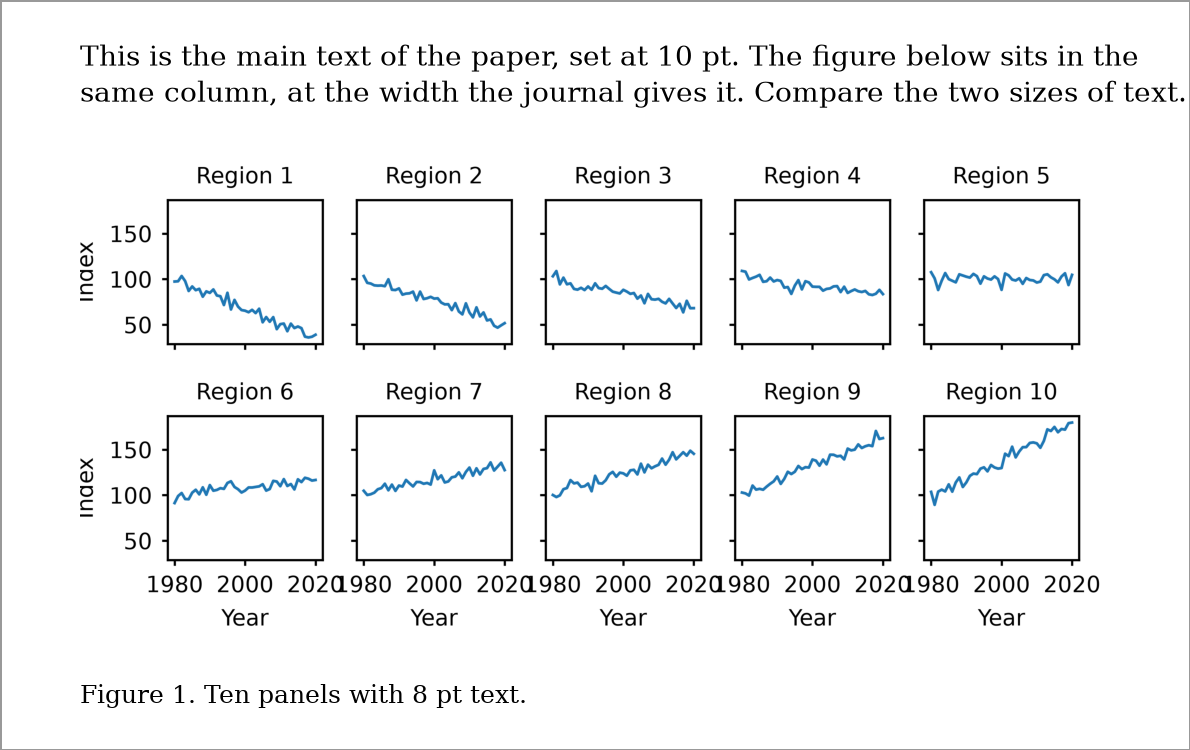

In [16]:
def grid():
    rng = np.random.default_rng(4)
    fig, axes = plt.subplots(2, 5, figsize=(PAGE, 2.5), sharex=True, sharey=True, dpi=200)
    fig.subplots_adjust(left=0.085, right=0.97, top=0.9, bottom=0.18, wspace=0.22, hspace=0.5)
    years = np.arange(1980, 2021)
    for k, ax in enumerate(axes.flat):
        ax.plot(years, 100 + (k - 4) * 0.4 * (years - 1980) + rng.normal(0, 4, years.size), linewidth=1)
        ax.set_title(f"Region {k + 1}", fontsize=8)
        ax.tick_params(labelsize=8, length=2)
        ax.set_xticks([1980, 2000, 2020])
    for ax in axes[1]:
        ax.set_xlabel("Year", fontsize=8)
    for ax in axes[:, 0]:
        ax.set_ylabel("Index", fontsize=8)
    return fig

small = grid()
on_the_page(small, PAGE, "Ten panels with 8 pt text.");

The years under one panel run into the years under the next, and the text crowds out the data.
The text should be smaller here, but how much smaller?

figfont's rule: **a panel should be at least 15 text heights wide**, that is, 15 times as wide as
its own text is tall. `density` measures that for every panel.

In [17]:
crowding = figfont.density(small)

print(f"The narrowest panel is {crowding['ems_min']:.0f} text heights wide. It should be 15 or more.")

The narrowest panel is 7 text heights wide. It should be 15 or more.


`suggest_size` turns that into a font size. It picks the size that makes the narrowest panel 15
text heights wide, but never goes under 6 pt, because smaller text is hard to read at all, and
never over 8 pt.

In [18]:
size = figfont.suggest_size(small, printed_pt=8)     # printed_pt: the size the text prints at now

print(f"Use {size:.0f} pt for this figure.")

Use 6 pt for this figure.


These panels would need under 4 pt to reach 15, so the answer is the 6 pt floor. `scale_fonts`
multiplies every font in the figure by one number, which takes the 8 pt text to 6 pt. Then `fit`
clears what still touches, this time printing what it does:

TEXT DENSITY grid: median 0.1129 ems 9.3 min 9.3 panels 0.1013 0.0000 0.0000 0.0000 0.0000 0.2258 0.1245 0.1245 0.1245 0.1245 | ems 9.3 9.3 9.3 9.3 9.3 9.3 9.3 9.3 9.3 9.3


TEXT FIXED grid: space 2


TEXT OK grid: no overlaps


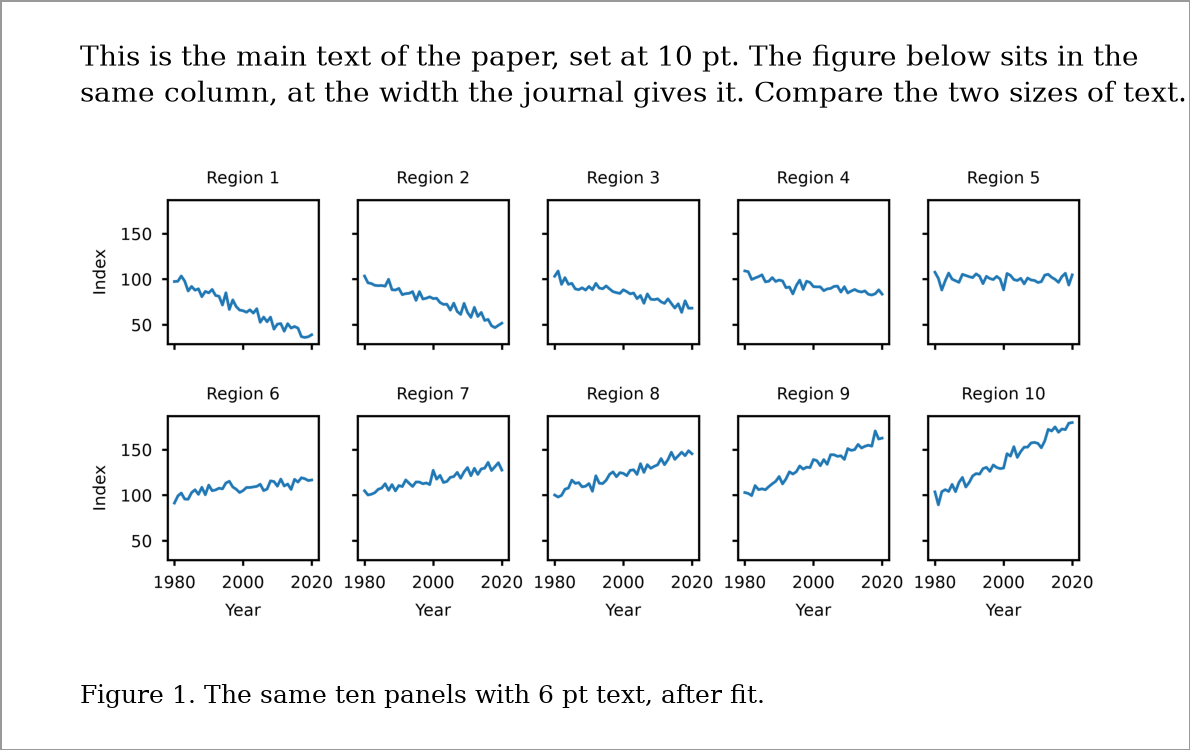

In [19]:
scale_fonts(small, size / 8)
left = figfont.fit(small, "grid")

on_the_page(small, PAGE, "The same ten panels with 6 pt text, after fit.");

How to read what `fit` printed:

| Line | Meaning |
|---|---|
| `TEXT DENSITY grid: ...` | The crowding measurement from above, taken before any change. The number after `min` is the width of the narrowest panel in text heights: about 9 now, up from 7. The other numbers are per panel and matter only if you are tuning the rule |
| `TEXT FIXED grid: space 2` | What it changed. `space` means it opened up room between the panels, and 2 is how many times it did that |
| `TEXT OK grid: no overlaps` | Nothing touches any more. If something were left, it would be listed here as in step 5 |

At 9 text heights the panels are still under the target of 15. Smaller text will not get them
there. Fewer panels in a row, or a wider figure, would.

The target of 15 was set by eye on the figures of one paper. Change it with `target=`.

## Labels on a map

A boxed note on a map, such as a season label, is placed by longitude and latitude. When the map
or the text changes size it ends up on a coastline. Here the top label touches the coast of
Central America.
(This part needs cartopy.)

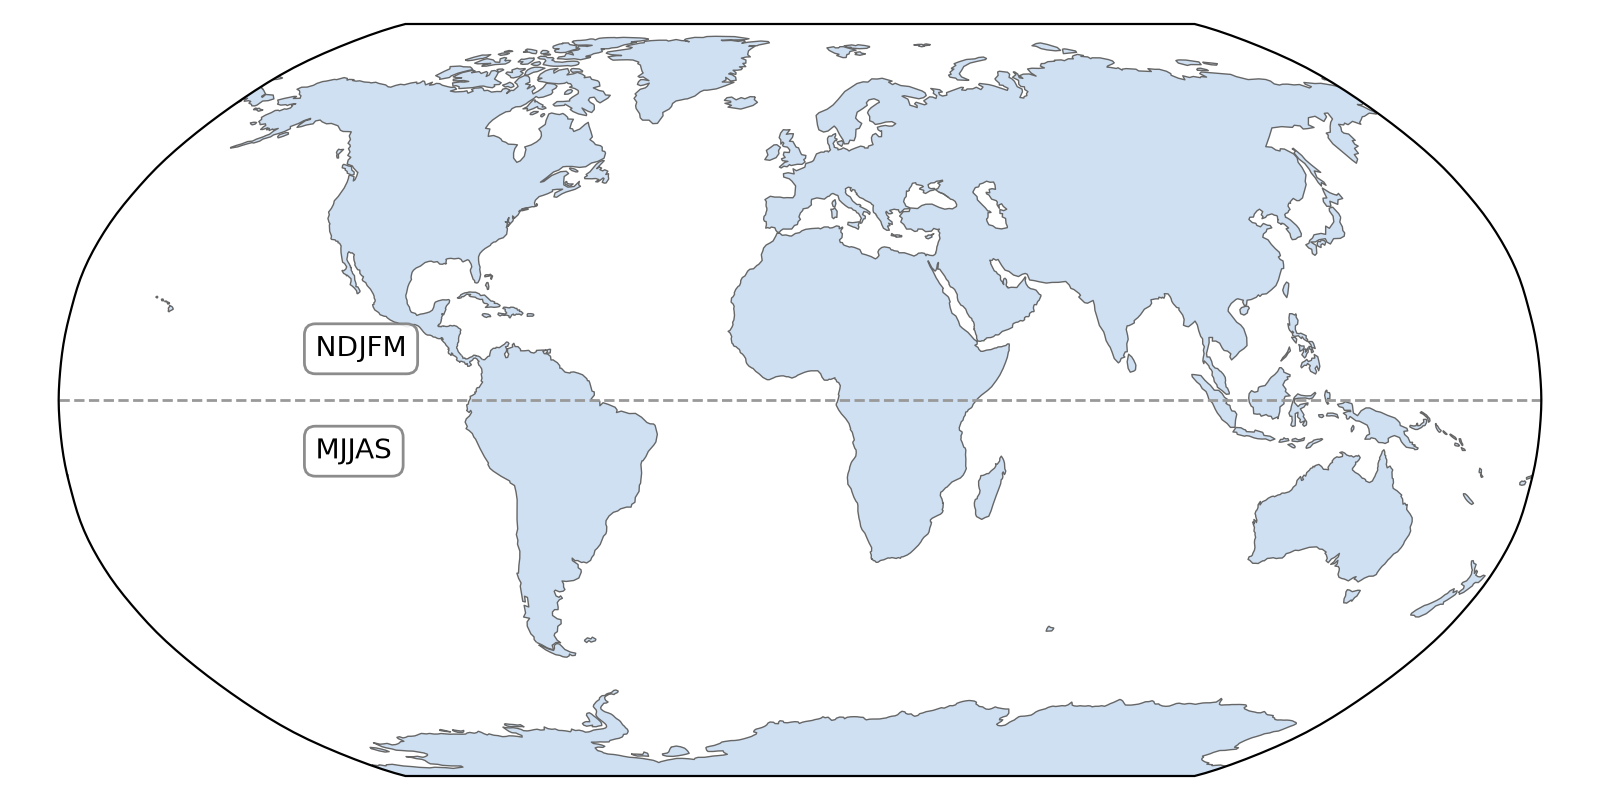

In [20]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

figfont.textfit.pad_cartopy_labels()   # once, before drawing: keeps cartopy's own coordinate labels apart

world = plt.figure(figsize=(8, 4))
ax = world.add_axes([0.02, 0.03, 0.96, 0.94], projection=ccrs.Robinson())
ax.set_global()
ax.add_feature(cfeature.LAND, facecolor="#cfe0f3")
ax.coastlines(linewidth=0.5, color="0.4")
ax.plot([-180, 180], [0, 0], "--", color="0.6", linewidth=1, transform=ccrs.PlateCarree())   # the equator
box = dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.5", alpha=0.9)
ax.text(-118, 8, "NDJFM", transform=ccrs.PlateCarree(), ha="left", va="bottom", bbox=box, zorder=10)
ax.text(-118, -8, "MJJAS", transform=ccrs.PlateCarree(), ha="left", va="top", bbox=box, zorder=10);

`clear_notes` moves a boxed note that touches something drawn the shortest way clear of it. Notes
lined up with it move too, so they stay lined up. A note never crosses a line drawn right across
the map, so each label stays on its own side of the equator.

2 notes moved. 0 could not be placed.


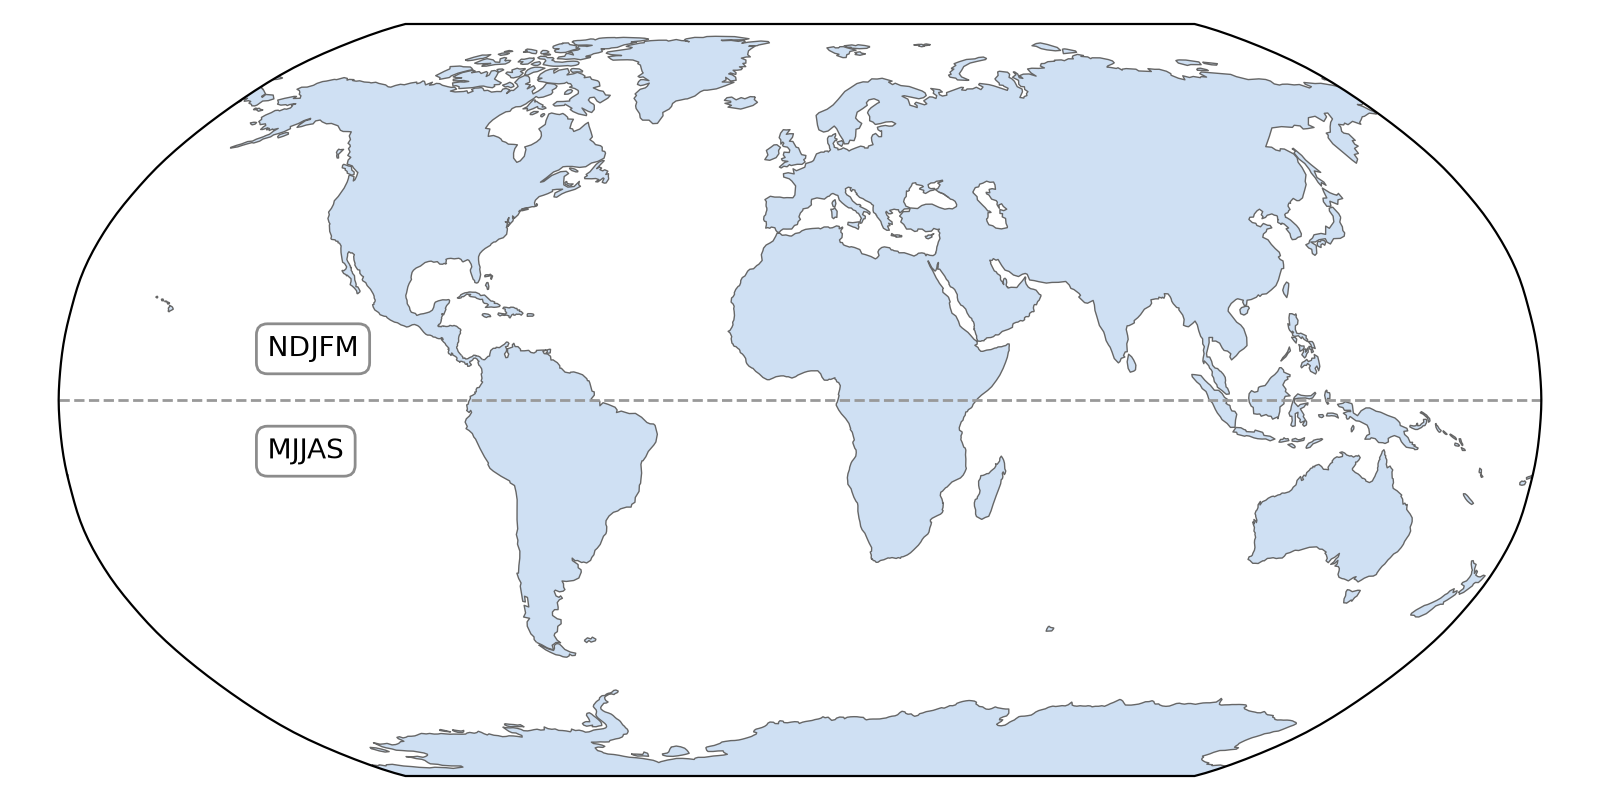

In [21]:
moved, stuck = figfont.clear_notes(world)
print(f"{moved} notes moved. {len(stuck)} could not be placed.")
world

Both labels moved left by the same amount. `fit` does this as its last step, so you only call
`clear_notes` yourself when it is the one thing you want.

## A figure you only have as a file

**An image.** A co-author sends a PNG, or the figure came out of other software. `figfont.figure`
takes it the same way. An image holds no font sizes, only pixels, so figfont reads the text off
the picture (OCR) and measures the height of the letters.

In [22]:
from_image = figfont.figure(out / "fig01.png", printed_width=PAGE)

print(f"From the PNG: typical text {from_image.median} pt, by {from_image.method}.")
print(f"From the PDF: typical text {final.median} pt, by {final.method}.")

From the PNG: typical text 6.81 pt, by ocr.
From the PDF: typical text 7.0 pt, by text.


The image answer is close to the exact one from the PDF, not equal to it. It is good enough to
tell 4 pt from 8 pt, which is what matters. If you have the choice, measure a PDF.

(`figure` picks between two functions by the kind of file. You can call them yourself:
`figure_pdf_text` for a PDF and `figure_ocr` for an image.)

**The whole paper.** Before you submit, check every figure at once in the compiled paper.
`pdf_figure_text` takes the text that sits on a drawing and is in a different font from the
paper's main text, which leaves out the main text and the captions. It needs no page width,
because the figures are already at their printed size. It can only read figures that went into
the paper as PDFs: a figure that went in as an image has no text in it, so measure that one from
its own file. The paper here is a one-page example kept in this repository.

In [23]:
paper = figfont.pdf_figure_text("examples/paper.pdf")

print(f"{paper.n} pieces of figure text in the paper. Typical {paper.median} pt, small end {paper.percentile(10)} pt.")

45 pieces of figure text in the paper. Typical 7.0 pt, small end 7.0 pt.


**Without Python.** The same checks run from a terminal. `figfont check` takes figure files and a
page width:

In [24]:
!figfont check tour_output/draft.pdf tour_output/fig01.pdf --width 5.15

published papers: median 7.97 pt, middle half of papers 7.39-8.97 pt
  draft.pdf                        median  3.96 pt (1.0 mm caps)  p10  3.96  SMALL  x2.01
  fig01.pdf                        median  7.00 pt (1.7 mm caps)  p10  7.00  SMALL  x1.14


The first line is the published papers. Then one line for each file: its typical size, the
height of a capital letter on the page in millimetres, the small end (`p10`), the verdict, and
the number to multiply the fonts by to match the published papers.

`figfont paper` does the same for a compiled paper, and `--journal` compares with one journal:

In [25]:
!figfont paper examples/paper.pdf --journal "Nature"

published papers: median 7.0 pt, middle half of papers 6.0-7.0 pt
  paper.pdf                        median  7.00 pt (1.7 mm caps)  p10  7.00  OK     x1.0


## Working out sizes by hand

Sometimes you want the number, not a changed figure: to set a font size in other software, or to
plan a figure before drawing it.

In [26]:
print(f"10 pt text on a {DRAWN} in figure prints at {figfont.printed_pt(10, DRAWN, PAGE):.1f} pt on a {PAGE} in page.")
print(f"To print at 8 pt, draw the text at {figfont.drawn_pt_for(8, DRAWN, PAGE):.1f} pt.")
print(f"Text that prints at 4 pt needs every font multiplied by {figfont.font_scale_for(8, 4):.1f} to print at 8 pt.")

10 pt text on a 13 in figure prints at 4.0 pt on a 5.15 in page.
To print at 8 pt, draw the text at 20.2 pt.
Text that prints at 4 pt needs every font multiplied by 2.0 to print at 8 pt.


Some figures are put together from panels that are drawn and saved one at a time. Each panel then
needs its own printed width. For three panels side by side on the 5.15 in page, with a 0.15 in gap
between them and a 0.1 in margin:

In [27]:
panel = figfont.panel_width_for(PAGE, columns=3, gap=0.15, margin=0.1)
whole = figfont.stitched_width(panel, columns=3, gap=0.15, margin=0.1)

print(f"Each panel prints {panel} in wide. Three of them make a figure {whole} in wide.")

Each panel prints 1.55 in wide. Three of them make a figure 5.15 in wide.


So a panel drawn on its own gets `set_printed_fonts(panel_fig, printed_width=1.55)`, not 5.15.

## Where next

The [README](../README.md) is the reference: every function with its options, each of the ten
changes `fit` can make, and what OCR can and cannot measure.